<a href="https://colab.research.google.com/github/judithwang021/judith-6070/blob/main/WeeklyModules/Week10/judithwang021_participation10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import statsmodels.formula.api as sm
import statsmodels.api as se
import seaborn as sns
import datetime as dt
from sklearn.linear_model import LinearRegression
from scipy import stats
from io import StringIO
import itertools
from pathlib import Path
!pip -q install dataframe_image
import dataframe_image as dfi

pd.set_eng_float_format(accuracy=3, use_eng_prefix=True)
pd.set_option('display.float_format', lambda x: '%.2f' % x)

from google.colab import userdata
import os

github_token = userdata.get('github_token')
owner = 'judithwang021' # Replace with the GitHub repository owner
repository = 'judith-6070' # Replace with the GitHub repository name

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository
import subprocess
subprocess.run(['git', 'clone', clone_url])

# Navigate into the cloned repository directory (optional, but often useful)
os.chdir(repository)
print(f"Changed directoGit_HUBry to: {os.getcwd()}")

Changed directoGit_HUBry to: /content/judith-6070


In [2]:
import geopandas as gpd
from numpy import float64
!pip -q install geopandas folium mapclassify

In [3]:
csv_path = Path("/content/judith-6070/data/CA_Legislative_Districts.csv")
geojson_path = Path('/content/judith-6070/data/california-congressional-districts.geojson')

In [4]:
df = pd.read_csv(csv_path)
district = gpd.read_file(geojson_path)
df.head()

,OBJECTID,ID,AREA,DISTRICT,MEMBERS,NAME,POPULATION,CVAP_19,HSP_CVAP_1,DOJ_NH_BLK,...,MULTIPLE_F,F_CVAP_19,F_HSP_CVAP,F_DOJ_NH_B,F_DOJ_NH_A,F_NH_WHT_C,DISTRICT_L,DISTRICT_N,SHAPE_Length,SHAPE_Area
0,1,1,27014.63,1,1,MTCAP,760066,549203,77031,10923,...,1|0,0.72,0.14,0.02,0.05,0.75,1|0%,1,2633905.97,122295210592.51
1,2,2,560.65,10,1,STANI,760066,503249,67160,26317,...,10|0,0.66,0.13,0.05,0.17,0.62,10|0%,10,358288.98,2336909010.62
2,3,3,226.43,11,1,COCO,760067,568460,61171,33907,...,11|1,0.75,0.11,0.06,0.32,0.50,11|0%,11,211193.17,940405406.89
3,4,4,141.25,12,1,SF,760065,510978,74038,101894,...,12|-1,0.67,0.14,0.20,0.21,0.42,12|-0%,12,124678.58,586947590.58
4,5,5,6346.92,13,1,OKLND,760065,393416,197645,16042,...,13|-1,0.52,0.50,0.04,0.06,0.37,13|-0%,13,1186867.65,25781145591.73


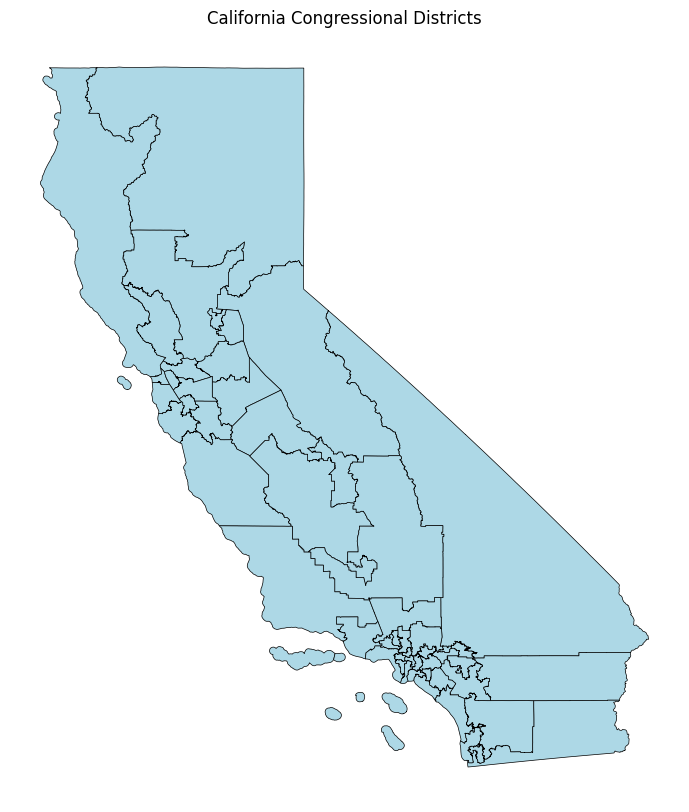

In [5]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1)

district.plot(
    ax=ax,
    color='lightblue',
    edgecolor='black',
    linewidth=0.5)

ax.set_title('California Congressional Districts')
ax.set_axis_off()

plt.show()

In [6]:
df['NAME'].describe()

,NAME
count,52
unique,52
top,MTCAP
freq,1


In [7]:
df['DISTRICT_N'].describe()

,DISTRICT_N
count,52.00
mean,26.50
std,15.15
min,1.00
25%,13.75
50%,26.50
75%,39.25
max,52.00


In [8]:
district['DISTRICT'] = district['Name'].astype(int)

In [9]:
population = district.merge(df[['DISTRICT', 'POPULATION']], on='DISTRICT', how='left')

In [10]:
population['POPULATION'].isna().sum()

np.int64(1)

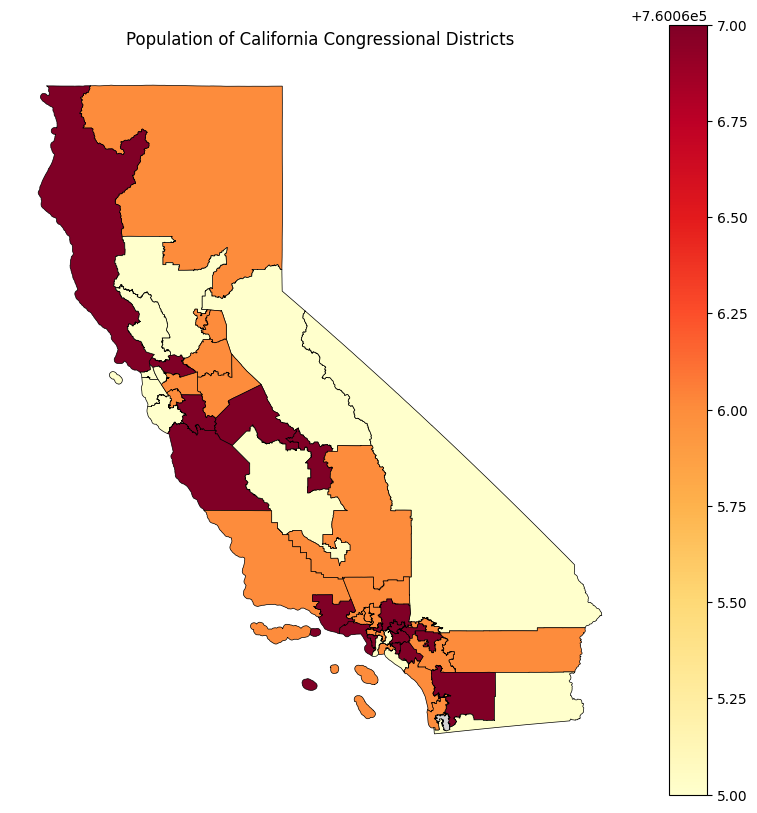

In [11]:
fig = plt.figure(figsize=(10, 10))
ax = fig.add_subplot(1, 1, 1)

population.plot(
    column='POPULATION',
    ax=ax,
    cmap='YlOrRd',
    legend=True,
    edgecolor='black',
    linewidth=0.5,
    missing_kwds={
        'color': 'lightgrey',
        'edgecolor': 'black',
        'label': 'No population data'})

ax.set_title('Population of California Congressional Districts')
ax.set_axis_off()

plt.show()